### CSE 5243 - Introduction to Data Mining
## Homework 1: CRISP_DM Steps 2-3 (with Exploratory Data Analysis)
- Semester: Autumn 2026
- Instructor: Stanley Vernier
- Section Tue/Thu 12:45PM
- Student Name: Zachary Petros
- Student Email: petros.28@osu.edu
- Student ID: 500749791

Based on CRISP-DM Template Version V11.

***
# Section: Overview
- Insert a short description of the scope of this exercise, any supporting information, etc.
- **(I will fill this in for each assignment - Tom Bihari)**
***

### Assignment Overview
In this assignment, you will analyze an ALTERED copy of the “Passenger Satisfaction” dataset.
- This dataset was pulled from: https://www.kaggle.com/datasets/johndddddd/customer-satisfaction
- The dataset file is named: **satisfaction_sv.csv**

**The data has been altered slightly for use in course assignments,etc.:**
- Errors have been added, such as: duplicated records, deleted attribute values, erroneous attribute values.

**DO NOT PUBLISH THIS DATASET - it contains intentionally wrong data!**

This assignment covers **steps two and three of the six steps** of the **CRISP-DM process model** (Data Understanding, Data Preparation). (See the CRISP-DM materials on CARMEN.)

The **objectives** of this assignment are:
- By analyzing and thinking critically about the data, you may identify interesting charcteristics that would be valuable when using the data.
- The final, cleaned-up dataset that you create may be used to build classification / regression models in assignments.

### Problem Statement
Assume that you are the Director of Data Science for Buckeye Airlines, Inc. (BAI).  BAI wants to improve its customer satisfaction.
- BAI performed a survey of passengers, to collect their opinions on a variety of aspects of BAI's services.
- BAI leadership has asked your team to analyze the new data, and determine if it is suitable for developing analyses and models that would be effective in predicting overall customer satisfaction (Note: This "overall satisfaction" attribute is the "class variable" we may eventually want to predict.  It is called **satisfaction_v2** in the dataset).
- Based on this, BAI may make improvements to specific aspects of their services, with a goal of improving BAI's overall customer satisfaction.

You decide to look at the dataset, **explore (understand)** what it contains, and **create (prepare)** a clean dataset from it that contains the kind of information you think might be useful.

You do not yet know the specific algorithm, formula or model you will use to predict satisfaction.  **That will come in a later step.**

### Things To Do
Complete **Sections 2 and 3** of CRISP-DM in this notebook (and the **Conclusion**). 
- **Data Understanding**: Perform Exploratory Data Analysis and gain an understanding of the contents and usefulness of the dataset. 
- **Data Preparation**: Clean up the data and save it for future use.

### Important Points
It is essential that you **communicate** your goals, thought process, actions, results, and conclusions to the **audience** that will consume this work.  It is **not enough** to show just the code.  It is not appropriate to show long sections of **unexplained printout**, etc.  Be kind to your readers and provide value to them!

**ALWAYS follow this pattern** when doing **each portion** of the work.  This allows us to give feedback and assign scores, and to give partial credit.  Make it easy for the reader to understand your work.
- Say (briefly) **what** you are trying to do, and **why**.
- Do it (code), and comment your code, so others can understand and evaluate it.
- Show or describe the **result** clearly (and briefly as needed), and explain the significant **conclusions or insights** derived from the results. 

**HAVE FUN!**

***
# Section: Setup
- Add any needed imports, helper functions, etc., here.
***

In [2]:
import numpy as np
import pandas as pd

#!pip install matplotlib
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
#matplotlib.use('Qt5Agg')

import seaborn as sns

pd.set_option('display.max_columns', 50) #include to avoid ... in middle of display

***
# Section: 1 - Business Understanding - SKIP THIS!
- This step is essential (and occasionally ignored…).  It focuses on understanding the business needs and objectives, and defining a data analysis problem that is relevant and useful to the business, so the right solution is built.

- Consider the following questions and discuss the possible answers to them in the spaces below.
  - It is OK to say that you do not know.  How might you get answers to the questions?
  - You may consider some of the questions to be "not applicable".  If so, why?
  - You may choose to use markdown instead of raw text in the answer cells, to make them "pretty" and easy to read.
***

**Context**
- What is the overview, history, big picture?

**Business Objectives**
- What is the problem or opportunity to be addressed / solved?
- What is its business value?

**Stakeholders**
- Who are they?
- What are their needs?

**General Goals**
- Understand the past/current state (descriptive)?
- Predict the future (predictive)?
- Mine for unknown patterns / insights?
- Answer questions?  What are they?
- Support decisions?  What are they?

**Scope**
- What is the specific scope of the project?
- What, specifically, is NOT in scope?  (What are you not doing that someone might think you are doing?)
Is the scope flexible?  In what way?

**Deliverables**
- Report?
- Reusable code?
- Presentation?

**Success Criteria**
- What, specifically, must be accomplished for this project to be a success?

**Solution Approach**
- Is this a “one time” (throw away) solution?
- Or will the solution become part of repeated process that is used and enhanced over time?

**Quality**
- What level of Correctness or Confidence is needed?
- Is this life-critical or are we looking for ‘directionally correct’ results?

**Constraints**
- Are there legal / regulatory implications (privacy, security, liability, HIPAA, FERPA)?
- Are there architectural constraints?

**Time / Cost**
- What is the deadline or budget?

**Dependencies**
- Is this project dependent on any other project or activity?
- Is any other project or activity dependent on this project?

**Resources Needed**
- Do you potentially need access to specific people, data, etc?

**Other Considerations**
- What other considerations, not covered above, might be relevant?

***
# Section: 2 - Data Understanding
- Perform exploratory data analysis of the dataset by looking at individual attributes and/or combinations of attributes. You should focus on identifying and describing interesting observations and insights that you might uncover from the data.
- You should not simply provide the basic EDA information for all attributes in the data. Instead, you should focus on those that are more interesting or important, and provide some discussion of what you observe. Pay particular attention to potentially interesting bivariate (two-variable) relationships, as well as the relationship between each attribute and the class attribute (if this is a classification problem).
- This step includes:
  - Understanding what data might be available and relevant.
  - Acquiring the data.
  - Understanding the characteristics of the data (e.g., quality, completeness, currency, consistency,…).
  - Understanding how other datasets might enhance or supplement the data (and acquiring that data as well).
  - Possibly performing some initial analysis to build confidence that the overall direction is likely to be helpful to the business problem to be solved.

**NOTE:** Frequently, a first pass is made through the data to fix or remove "obvious" data quality issues (missing values, duplicate records, outliers (some), etc.).  The deeper Data Understanding analysis then is done on the "cleaned" data.  This mitigates the issue of bad data skewing the data analysis results.  **You may choose to do this separate first pass.**
***

***
## Section: 2.1 - Describe the meaning and type of data for each attribute.

Identify the type of data for each attribute.
  - Categorical: Nominal, Ordinal
  - Numerical: Interval, Ratio
  - Other: Complex or unstructured data (e.g., text strings, images,...)
  
NOTES:
  - This determines what operations are "meaningful" for each attribute.  For example, you can't add two Ordinal attributes.
  - You can't always tell the attribute types from the data itself.  For example, an Integer attribute could be Ordinal or Interval.

Identify interesting characteristics of the data (e.g., quality, completeness, currency, consistency,…).
  - Is this dataset relevant and appropriate for the goals of this project?
    - If not, what could you do? (find other data to replace or supplement this dataset, etc.)
***

### **Examine the meta-data (e.g., from data dictionary) available for the dataset.**

**Examine the Metadata.**

Collect the information for each attribute.
  - Categorical: Nominal, Ordinal; Numerical: Interval, Ratio; Other: Complex or unstructured data (e.g., text strings, images,...)
  - This determines what operations are "meaningful" for each attribute.  For example, you can't add two Ordinal attributes.
  - You can't always tell the attribute types from the data itself.  For example, an Integer attribute could be Ordinal or Interval.

Create a table, such as:
| **Attribute** | **Type** | **DataType** | **UnitOfMeasure** | **Meaning** | **Notes** |
| --- | --- | --- | --- | --- | --- |
| ID | Ordinal | Integer | No Unit - Just an index | Record number; not real data | This is handy for documentation purposes |
| satisfaction_v2 | nominal | String | Category | Overall Passenger Satisfaction | Either Satisisfied or neutral/dissatisfied |
| gender | Nominal | String | Category | Passenger Gender | Male/Female |
| Customer Type | Nominal | String | Category | Loyal Customer or Not | n/a |
| Age | Ordinal | Integer | Years | Passenger's Age | Range 7-80 |
| Type of Travel | Nominal | String | Category | Purpose of Travel | Buisness or Personal |
| Class | Ordinal | String | Travel class | Passenger's airline seating/service class | Business, Eco Plus, or Eco |
| Flight Distance | Ratio | Integer | Distance | Distance of the passenger's flight | Unit is not explicitly specified in the data |
| Seat Comfort | Ordinal | Integer | Rating scale | Passenger's rating of seat comfort | Rating from 0–5 |
| Departure/Arrival time convenient | Ordinal | Integer | Rating scale | Rating of how convenient departure/arrival times were | Rating from 0–5 |
| Food and Drink | Ordinal | Integer | Rating scale | Passenger's rating of food and drink | Rating from 0–5 |
| Gate Location | Ordinal | Integer | Rating scale | Passenger's rating of gate location | Rating from 1–5 |
| Inflight Wifi | Ordinal | Integer | Rating scale | Passenger's rating of inflight Wi-Fi service | Rating from 1–5 |
| Inflight Entertainment | Ordinal | Integer | Rating scale | Passenger's rating of inflight entertainment | Rating from 0–5 |
| Online Support | Ordinal | Integer | Rating scale | Passenger's rating of online customer support | Rating from 1–5 |
| Ease of Booking Online | Ordinal | Integer | Rating scale | Passenger's rating of the online booking process | Rating from 1–5 |
| On board service | Ordinal | Integer | Rating scale | Passenger's rating of onboard service | Rating from 1–5 |
| Leg Room Service | Ordinal | Integer | Rating scale | Passenger's rating of available leg room/service | Rating from 0–5 |
| Baggage Handling | Ordinal | Integer | Rating scale | Passenger's rating of baggage handling | Rating from 1–5 |
| Checkin Service | Ordinal | Integer | Rating scale | Passenger's rating of the check-in process | Rating from 1–5 |
| Cleanliness | Ordinal | Integer | Rating scale | Passenger's rating of aircraft cleanliness | Rating from 1–5 |
| Online boarding | Ordinal | Integer | Rating scale | Passenger's rating of the online boarding process | Rating from 1–5 |
| Departure Delay | Ratio | Integer | minutes | Number of minutes the flight's departure was delayed | 0 means no departure delay |
| Arrival Delay | Ratio | Integer | minutes | Number of minutes the flight's arrival was delayed | 0 means no arrival delay |

Note any concerns, considerations, or questions regarding this data.

Fill in...

### **Load the Dataset.**

In [4]:
# Note: Edit the path here to match your setup.  The "tiny" dataset contains just a few records to make it quick to test code.  The "with_errors" dataset is for the actual assignment.
#data_df = pd.read_csv('Data/satisfaction_sv_tiny.csv')
data_df = pd.read_csv('Data/satisfaction_sv.csv')

# Note: Do not use the id attribute as data, and do not include it in any analyses.  It's only purpose is to support referring to a row in the data for documentation purposes, if any.

In [5]:
data_df.head().T

,0,1,2,3,4
id,1,2,3,4,5
satisfaction_v2,neutral or dissatisfied,satisfied,satisfied,satisfied,satisfied
Gender,Male,Female,Male,Male,Female
Customer Type,disloyal Customer,Loyal Customer,Loyal Customer,Loyal Customer,Loyal Customer
Age,48,35,41,50,49
Type of Travel,Business travel,Business travel,Business travel,Business travel,Business travel
Class,Business,Business,Business,Business,Business
Flight Distance,2211,840,879,1932,3512
Seat comfort,3,2,4,2,3
Departure/Arrival time convenient,3,2,4,2,3


In [6]:
data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129881 entries, 0 to 129880
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 129881 non-null  int64  
 1   satisfaction_v2                    129880 non-null  str    
 2   Gender                             129881 non-null  str    
 3   Customer Type                      129881 non-null  str    
 4   Age                                129881 non-null  int64  
 5   Type of Travel                     129881 non-null  str    
 6   Class                              129881 non-null  str    
 7   Flight Distance                    129881 non-null  int64  
 8   Seat comfort                       129881 non-null  int64  
 9   Departure/Arrival time convenient  129881 non-null  int64  
 10  Food and drink                     129881 non-null  int64  
 11  Gate location                      129881 non-null

**Discussion:**

From your examination of the metadata and the dataset, what is your conclusion about this dataset?  Does it appear (so far) to satisfy your needs?  Are there any concerns?

So far the data set does seem to satisfy our needs so far. There are a wide range of variables that would be useful for analysis that seem to have little to no problems. The Dataset also includes a large amount of observations which is important for our needs.`

***
## Section: 2.2 - Provide basic statistics for the attributes.
- For example: counts, percentiles, mean, median, standard deviation. The statistics should be relevant for the type of attribute.
***

In [7]:
data_df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,129881.0,NaN,NaN,NaN,64940.080697,37493.431002,1.0,32470.0,64940.0,97410.0,129880.0
satisfaction_v2,129880,4,satisfied,71085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,129881,2,Female,65900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,129881,2,Loyal Customer,106101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,129881.0,NaN,NaN,NaN,39.428038,15.11933,7.0,27.0,40.0,51.0,85.0
Type of Travel,129881,2,Business travel,89694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,129881,3,Business,62161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,129881.0,NaN,NaN,NaN,1981.408281,1027.111689,50.0,1359.0,1925.0,2544.0,6951.0
Seat comfort,129881.0,NaN,NaN,NaN,2.838575,1.393,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129881.0,NaN,NaN,NaN,2.990622,1.527241,0.0,2.0,3.0,4.0,5.0


**Discussion:**

For the basic statistics, the dataset has a large number of observations, so it should be useful for finding general patterns. The average passenger age is around 39 years old, and the average flight distance is about 1,981. Most service ratings seem to fall around 3 to 4 out of 5. Departure and arrival delays average around 15 minutes, but the median is 0, which means a lot of flights had no delay while a smaller number had much longer delays. Overall, the statistics make the dataset look reasonable to use, but the large delay values and some missing or inconsistent data should be kept in mind.

In [8]:
print("Number of observations:", len(data_df))

# Average age
print("Average Age:", data_df["Age"].mean())

# Average flight distance
print("Average Flight Distance:", data_df["Flight Distance"].mean())

# Service rating averages
rating_columns = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]

print("\nAverage Service Ratings:")
print(data_df[rating_columns].mean())

# Departure delay statistics
print("\nAverage Departure Delay:",
      data_df["Departure Delay in Minutes"].mean())

print("Median Departure Delay:",
      data_df["Departure Delay in Minutes"].median())

# Arrival delay statistics
print("\nAverage Arrival Delay:",
      data_df["Arrival Delay in Minutes"].mean())

print("Median Arrival Delay:",
      data_df["Arrival Delay in Minutes"].median())

# Satisfaction counts
print("\nSatisfaction Counts:")
print(data_df["satisfaction_v2"].value_counts())

Number of observations: 129881
Average Age: 39.42803797322164
Average Flight Distance: 1981.4082814268445

Average Service Ratings:
Seat comfort                         2.838575
Departure/Arrival time convenient    2.990622
Food and drink                       2.851972
Gate location                        2.990414
Inflight wifi service                3.249115
Inflight entertainment               3.383482
Online support                       3.519707
Ease of Online booking               3.472325
On-board service                     3.465064
Leg room service                     3.485891
Baggage handling                     3.695660
Checkin service                      3.340804
Cleanliness                          3.705746
Online boarding                      3.352592
dtype: float64

Average Departure Delay: 14.713838051755069
Median Departure Delay: 0.0

Average Arrival Delay: 15.091267144445817
Median Arrival Delay: 0.0

Satisfaction Counts:
satisfaction_v2
satisfied                  71

***
## Section: 2.3 - Visualize / analyze the most important or interesting attributes using appropriate techniques.
- For each visualization, provide an interpretation explaining why it is appropriate or interesting. What does each visualization tell us?
***

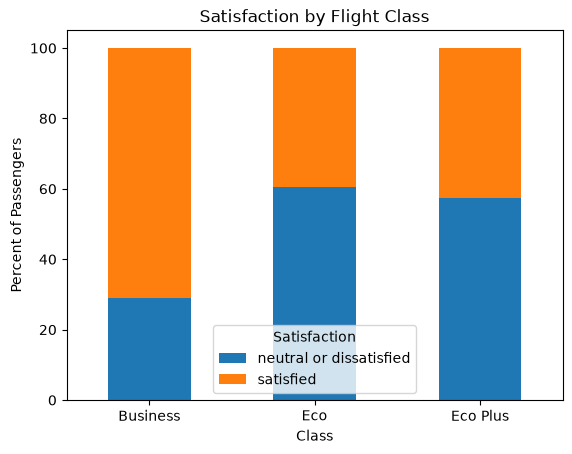

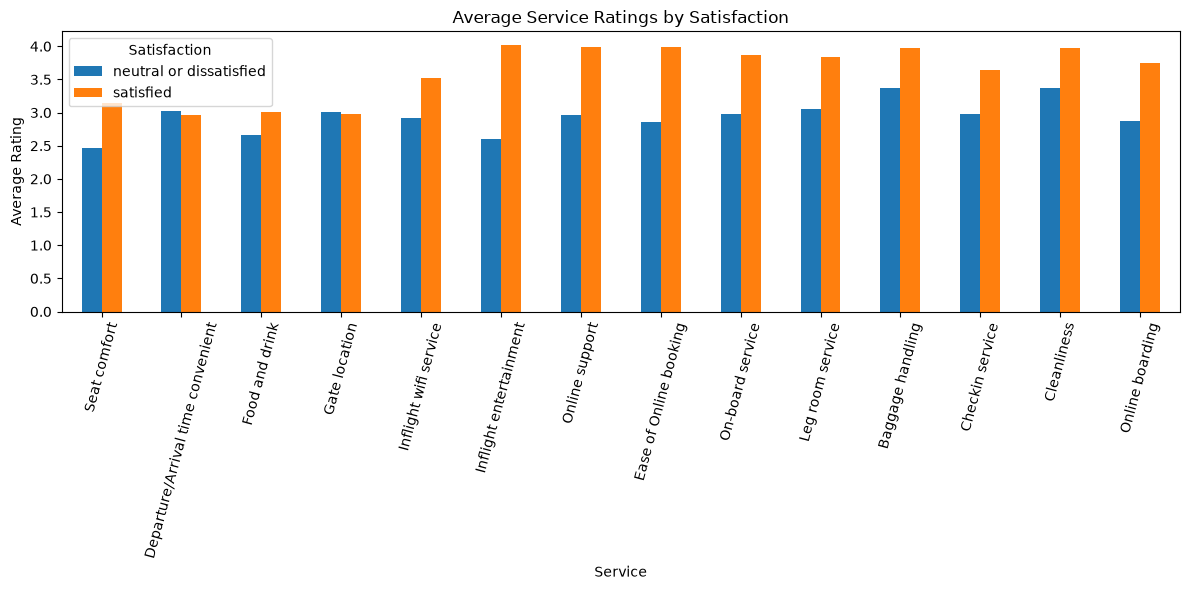

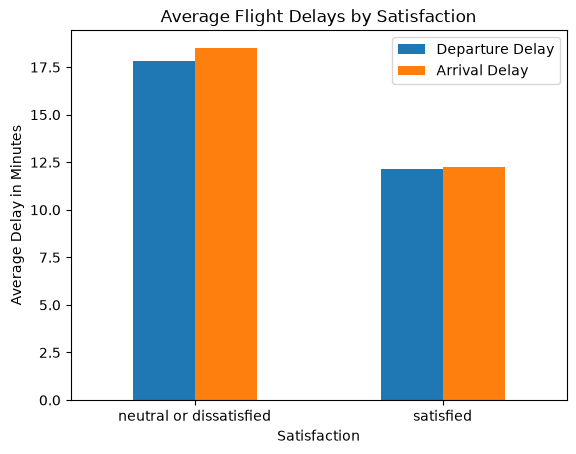

In [9]:
# Clean satisfaction column
data_df["satisfaction_v2"] = data_df["satisfaction_v2"].str.strip()
data_df["satisfaction_v2"] = data_df["satisfaction_v2"].replace("satisfed", "satisfied")


# 1. Satisfaction by Flight Class
class_sat = pd.crosstab(
    data_df["Class"],
    data_df["satisfaction_v2"],
    normalize="index"
) * 100

class_sat.plot(kind="bar", stacked=True)

plt.title("Satisfaction by Flight Class")
plt.xlabel("Class")
plt.ylabel("Percent of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()


# 2. Average Service Ratings by Satisfaction

rating_means = data_df.groupby("satisfaction_v2")[rating_columns].mean().T

rating_means.plot(kind="bar", figsize=(12, 6))

plt.title("Average Service Ratings by Satisfaction")
plt.xlabel("Service")
plt.ylabel("Average Rating")
plt.xticks(rotation=75)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()


# 3. Average Flight Delays by Satisfaction
delay_means = data_df.groupby("satisfaction_v2")[
    ["Departure Delay in Minutes", "Arrival Delay in Minutes"]
].mean()

delay_means.plot(kind="bar")

plt.title("Average Flight Delays by Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Average Delay in Minutes")
plt.xticks(rotation=0)
plt.legend(["Departure Delay", "Arrival Delay"])
plt.show()

**Discussion:**

The first graph compares satisfaction by flight class. A stacked bar graph works well because both variables are categorical. Business class has a higher percentage of satisfied passengers than Eco and Eco Plus, which suggests flight class may be related to overall satisfaction.

The second graph compares average service ratings by satisfaction. Satisfied passengers generally gave higher ratings across most service categories, especially for areas like inflight entertainment, online support, and online booking. This suggests that service quality has a strong connection to overall passenger satisfaction.

The last graph compares average departure and arrival delays by satisfaction. Neutral or dissatisfied passengers experienced longer delays on average than satisfied passengers. This suggests that delays may also have an effect on passenger satisfaction.

Overall, the graphs show that flight class, service ratings, and delays all appear to have some relationship with passenger satisfaction.

***
## Section: 2.4 - Verify data quality: explain any missing values, duplicate data, or outliers.
- What, if anything, do you need to do about these? Be specific.
***

In [10]:
# Check for missing values
print("Missing Values:")
print(data_df.isnull().sum())

# Check for duplicate rows
print("\nNumber of Duplicate Rows:")
print(data_df.duplicated().sum())

# Check satisfaction values for spelling/spacing problems
print("\nSatisfaction Values:")
print(data_df["satisfaction_v2"].value_counts(dropna=False))


print("\nValues Outside the Expected 0-5 Rating Scale:")
for column in rating_columns:
    invalid = data_df[(data_df[column] < 0) | (data_df[column] > 5)]
    
    if len(invalid) > 0:
        print(column, ":", invalid[column].unique())

# Look at possible outliers in distance and delays
print("\nFlight Distance and Delay Statistics:")
print(data_df[
    [
        "Flight Distance",
        "Departure Delay in Minutes",
        "Arrival Delay in Minutes"
    ]
].describe())

Missing Values:
id                                     0
satisfaction_v2                        1
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Seat comfort                           0
Departure/Arrival time convenient      0
Food and drink                         0
Gate location                          0
Inflight wifi service                  1
Inflight entertainment                 0
Online support                         0
Ease of Online booking                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Online boarding                        0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393


**Discussion:**

There are a few data quality issues that should be cleaned before further analysis. There are 393 missing values for Arrival Delay, along with one missing value for both satisfaction_v2 and Inflight wifi service. Since there are over 129,000 rows, removing the few rows with missing values should not have much effect on the dataset. There is also one duplicate row, which should be removed.

There are a couple of inconsistent values in satisfaction_v2, including satisfed and satisfied , which should both be changed to satisfied. There is also one value of 33 for Ease of Online booking, even though the rating scale should only go from 0–5, so this value should be treated as invalid. Some flight distances and delays are statistical outliers, but they are still realistic values, so I would keep those unless there is evidence that they were entered incorrectly.

***
## Section: 2.5 - Explore the relationships among the attributes.
- You may include or exclude the class attribute as appropriate.
- Use scatter plots, correlation matrices, cross-tabulations, group-wise averages, or other appropriate techniques. Explain and interpret any interesting relationships.
- There are three general cases for 2-attribute relationships:
  - Categorical vs Categorical
  - Categorical vs Numerical
  - Numerical vs Numerical
- See these references for additional guidance:
  - https://www.scribbr.com/statistics/statistical-tests/
  - https://researcher.life/blog/article/independent-vs-dependent-variables-definition-examples/
  - https://medium.com/@outside2SDs/an-overview-of-correlation-measures-between-categorical-and-continuous-variables-4c7f85610365
***

Satisfaction by Customer Type:
satisfaction_v2    neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                       38.37      61.63
disloyal Customer                    76.03      23.97


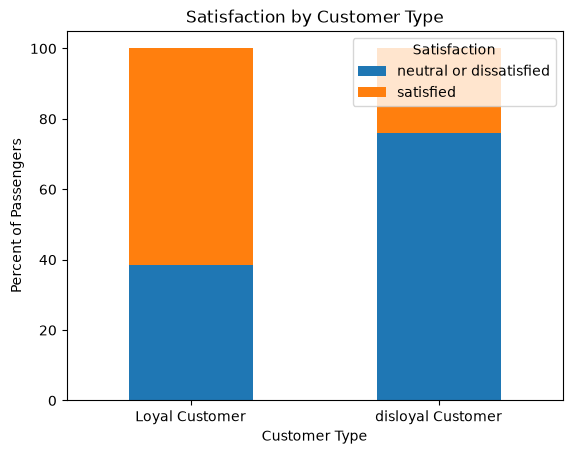


Average Flight Distance by Class:
Class
Business    2157.84
Eco         1824.25
Eco Plus    1789.76
Name: Flight Distance, dtype: float64


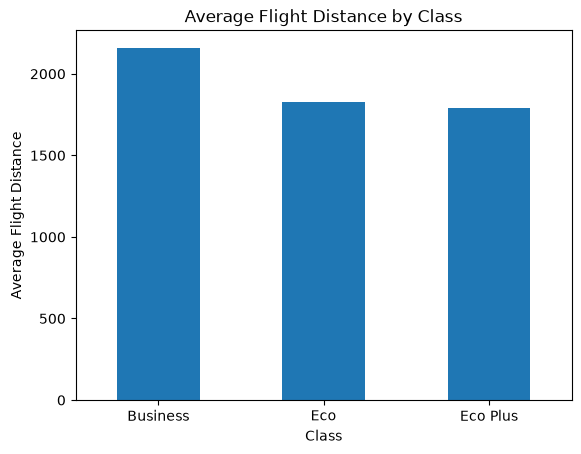


Delay Correlation:
                            Departure Delay in Minutes  \
Departure Delay in Minutes                       1.000   
Arrival Delay in Minutes                         0.965   

                            Arrival Delay in Minutes  
Departure Delay in Minutes                     0.965  
Arrival Delay in Minutes                       1.000  


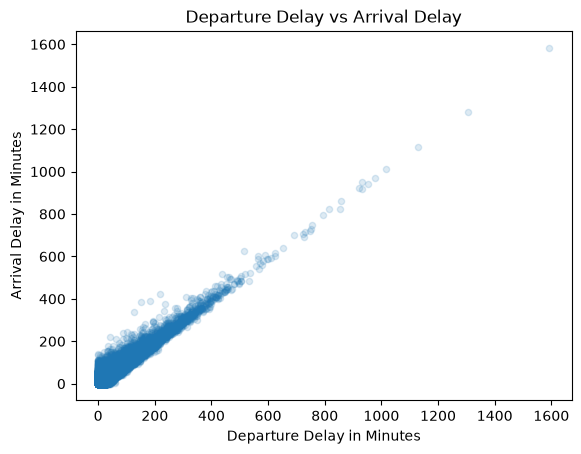

In [11]:
customer_sat = pd.crosstab(
    data_df["Customer Type"],
    data_df["satisfaction_v2"],
    normalize="index"
) * 100

print("Satisfaction by Customer Type:")
print(customer_sat.round(2))

customer_sat.plot(kind="bar", stacked=True)
plt.title("Satisfaction by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Percent of Passengers")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()


# 2. Categorical vs Numerical
# Compare average flight distance between flight classes
class_distance = data_df.groupby("Class")["Flight Distance"].mean()

print("\nAverage Flight Distance by Class:")
print(class_distance.round(2))

class_distance.plot(kind="bar")
plt.title("Average Flight Distance by Class")
plt.xlabel("Class")
plt.ylabel("Average Flight Distance")
plt.xticks(rotation=0)
plt.show()


# 3. Numerical vs Numerical
# Compare departure delay with arrival delay
delay_corr = data_df[
    ["Departure Delay in Minutes", "Arrival Delay in Minutes"]
].corr()

print("\nDelay Correlation:")
print(delay_corr.round(3))

data_df.plot.scatter(
    x="Departure Delay in Minutes",
    y="Arrival Delay in Minutes",
    alpha=0.15
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay in Minutes")
plt.ylabel("Arrival Delay in Minutes")
plt.show()

**Discussion:**

The first graph compares customer type and satisfaction. Loyal customers have a much higher percentage of satisfied passengers than disloyal customers. This shows that customer type has a pretty noticeable relationship with overall satisfaction.

The second graph compares flight class and average flight distance. Business class passengers have the highest average flight distance, while Eco and Eco Plus are lower. This could mean that passengers on longer flights are more likely to be flying Business class.

The last graph compares departure delay and arrival delay. These two variables have a very strong positive relationship, with a correlation of about 0.97. This means that when a flight leaves late, it will usually also arrive late.

***
## Section: 2.6 - Identify and explain any interesting relationships between the class attribute and the other attributes.
- You may refer to earlier analyses / visualizations (if you included the class attribute above) or create new ones.
***

**Discussion:**

For the class attribute, I looked at how satisfaction_v2 relates to some of the other variables in the dataset. One of the clearest relationships is with the service ratings. Satisfied passengers usually gave higher ratings for things like inflight entertainment, online support, booking, and cleanliness.

There is also a pretty clear difference between satisfaction and flight class. Business class passengers had a higher percentage of satisfied passengers than Eco and Eco Plus passengers. Loyal customers were also more likely to be satisfied than disloyal customers.

Another relationship is with flight delays. Passengers who were neutral or dissatisfied had longer departure and arrival delays on average. Overall, service ratings, flight class, customer type, and delays all seem to have some relationship with passenger satisfaction.

***
# Section: 3 - Data Preparation
In this step, the “final” target dataset is constructed (although nothing is ever final…), based on the insights gleaned in the Data Understanding step.
This may include:
- Normalizing / standardizing the data.
- Handling missing and erroneous data.
- Transforming or eliminating attributes.
- “Blending” data from multiple sources (with attention to consistency of the various sources).
- Deploying the data to storage in suitable formats, data models / structures.

**NOTE:** In each of these sections, it is OK to decide to **not** make changes to the dataset, but you **must** explain **why** you made the choice.  Recall that the purpose of this step is to produce a clean dataset that is suitable for the intended purposes.  So, for example, you might choose to not remove any attributes, but if you have 100 apparently irrelevant attributes, explain why are you keeping them - there may be a good reason.
***

***
## Section: 3.1 - Clean the Data
- Implement any data cleaning steps previously identified.  Please justify.
- Show the effects of that cleaning through the use of appropriate statistics and/or visualizations.
***

In [12]:
# Save the original size for comparison
print("Rows before cleaning:", len(data_df))
print("Duplicate rows before cleaning:", data_df.duplicated().sum())
print("Missing values before cleaning:")
print(data_df.isnull().sum()[data_df.isnull().sum() > 0])

# Fix inconsistent satisfaction values
data_df["satisfaction_v2"] = data_df["satisfaction_v2"].str.strip()
data_df["satisfaction_v2"] = data_df["satisfaction_v2"].replace(
    "satisfed", "satisfied"
)

# Replace invalid booking ratings with missing
data_df.loc[
    (data_df["Ease of Online booking"] < 0) |
    (data_df["Ease of Online booking"] > 5),
    "Ease of Online booking"
] = pd.NA

# Remove duplicate rows
data_df = data_df.drop_duplicates()

# Remove rows containing missing values
data_df = data_df.dropna()

# Show results after cleaning
print("\nRows after cleaning:", len(data_df))
print("Duplicate rows after cleaning:", data_df.duplicated().sum())

print("\nMissing values after cleaning:")
print(data_df.isnull().sum().sum())

print("\nSatisfaction values after cleaning:")
print(data_df["satisfaction_v2"].value_counts())

print("\nEase of Online Booking range:")
print("Minimum:", data_df["Ease of Online booking"].min())
print("Maximum:", data_df["Ease of Online booking"].max())

Rows before cleaning: 129881
Duplicate rows before cleaning: 1
Missing values before cleaning:
satisfaction_v2               1
Inflight wifi service         1
Arrival Delay in Minutes    393
dtype: int64

Rows after cleaning: 129484
Duplicate rows after cleaning: 0

Missing values after cleaning:
0

Satisfaction values after cleaning:
satisfaction_v2
satisfied                  70880
neutral or dissatisfied    58604
Name: count, dtype: int64

Ease of Online Booking range:
Minimum: 0.0
Maximum: 5.0


**Discussion:**

All previously identified cleaning steps completed. Misinputted data and rows with missing data fixed/removed.

***
## Section: 3.2 - Select Attributes
- Optionally, remove attributes that are unneeded, redundant, etc., for the expected uses.
- Which attributes did you decide to remove, if any? Please justify.
***

In [13]:
# Show columns before removing attributes
print("Columns before:")
print(data_df.columns)

# Remove unnecessary/redundant attributes
data_df = data_df.drop(
    columns=["id", "Arrival Delay in Minutes"]
)

# Show columns after removing attributes
print("\nColumns after:")
print(data_df.columns)

print("\nNumber of attributes remaining:", data_df.shape[1])

Columns before:
Index(['id', 'satisfaction_v2', 'Gender', 'Customer Type', 'Age',
       'Type of Travel', 'Class', 'Flight Distance', 'Seat comfort',
       'Departure/Arrival time convenient', 'Food and drink', 'Gate location',
       'Inflight wifi service', 'Inflight entertainment', 'Online support',
       'Ease of Online booking', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness', 'Online boarding',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes'],
      dtype='str')

Columns after:
Index(['satisfaction_v2', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Seat comfort',
       'Departure/Arrival time convenient', 'Food and drink', 'Gate location',
       'Inflight wifi service', 'Inflight entertainment', 'Online support',
       'Ease of Online booking', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness', 'Online boarding',
   

**Discussion:**

I removed the ID column because it has no use to anything the data would be used for. Interestingly though, i removed Arrival Delay in Minutes since it was strongly coorelated with departure delay which means I would only need to use one of the in a model. I chose to remove arrival delay because the data was messier and, personally, I feel like departure delay would be a more useful attribute.

***
## Section: 3.3 - Create Attributes
- Optionally, create new attributes based on the values of other attibutes.
- Which new attributes did you decide to create, if any? Please justify.
***

In [14]:
satisfaction_columns = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]
# Create a new column with the average service rating for each passenger
data_df["Average Satisfaction Rating"] = data_df[satisfaction_columns].mean(axis=1)

# Check the new column
print(data_df[["Average Satisfaction Rating"]].head())

   Average Satisfaction Rating
0                     3.857143
1                     3.785714
2                     3.928571
3                     3.785714
4                     3.500000


**Discussion:**

I decided to make an attribute averaging all the satisfactions together. This seems like a useful predictor that might be useful to creating a model over this data.

***
## Section: 3.4 - Transform Attributes
- Optionally, transform existing attributes (e.g., standardize, normalize, change units of measure, encode) to make them more appropriate for the expected uses.
- Which attributes did you decide to transform, if any? Please justify.
***

**Discussion:**

I did not decide that any of the attributes needed transformed to be used for their expected uses

***
## Section: 3.5 - Select Records
- Optionally, select a subset of the records, via sampling, etc., to decrease the size of the dataset. Please justify.
***

**Discussion:**

I decided not to reduce the number of samples because the dataset is still manageable and keeping all observations gives a more complete representation of the data. Sampling could be useful for certain visualizations, but it is not necessary for the main analysis especially when writing code. Creating subsets is more useful if you are doing analysis by hand.

***
## Section: 3.6 - Other Data Preparation
- Optionally, perform other preparation steps (e.g., to optimize storage, retrieval, etc.). Please justify.
***

**Discussion:**

Considering that this data set is already quite small in terms of file size, I decided not to do any more preperation steps for storage. I am also quite happy with the data itself and this is a data set that I would work on a project with, for these reasons I decided not to do any more Data preparation.

***
# Section: 4 - Modeling - SKIP THIS!
In this step, the dataset is analyzed and used to create models and/or answer questions relevant to the business. This may include:
- Developing statistical models for describing or predicting business situations.
- Training data mining (e.g., machine learning) algorithms for classification, clustering, association analysis, outlier detection, and other uses.

NOTE: This step is tightly coupled and iterative with the Data Preparation and Evaluation steps.
***

**Discussion:**

Fill in...

***
# Section: 5 - Evaluation - SKIP THIS!
In this step, the analyses and/or models are evaluated for quality and relevance / usefulness.

NOTE: This step is tightly coupled and iterative with the Modeling step.
***

**Discussion:**

Fill in...

***
# Section: 6 - Deployment - SKIP THIS!
In this step, data and resulting models and/or analyses are put to use. This may include:
- Deploying data mining / machine learning algorithms to production.
- Communicating the results of the analyses to business stakeholders, so they can take action.
***

**Discussion:**

Fill in...

***
# Section: Conclusions
- What did you learn from this exercise?
***

**Discussion:**

Fill in...